In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = '../data/processed/merged_cleaned_2019.csv'

member_col = ['club_member_status','product_group_name','price']

df = pd.read_csv(path,usecols=member_col)

 


In [3]:
df['club_member_status'].value_counts()



club_member_status
ACTIVE        15997833
PRE-CREATE      363620
Unknown          30007
LEFT CLUB         5470
Name: count, dtype: int64

In [ ]:

price_stats = (df.groupby('club_member_status')['price']
                 .agg(['count', 'mean', 'median', 'std'])
                 )

price_stats['mean_vs_active_pct'] = (price_stats['mean'] / price_stats.loc['ACTIVE', 'mean'] - 1) * 100
price_stats['mean_vs_median_pct'] = (price_stats['mean'] / price_stats['median'] - 1) * 100
price_stats.round(4)


,count,mean,median,std,mean_vs_active_pct,mean_vs_median_pct
club_member_status,,,,,,
ACTIVE,15997833,0.0277,0.0254,0.0193,0.0000,9.1247
PRE-CREATE,363620,0.0303,0.0254,0.0203,9.2019,19.1663
LEFT CLUB,5470,0.0295,0.0254,0.0221,6.3341,16.0368
Unknown,30007,0.0298,0.0254,0.0215,7.3970,17.1967


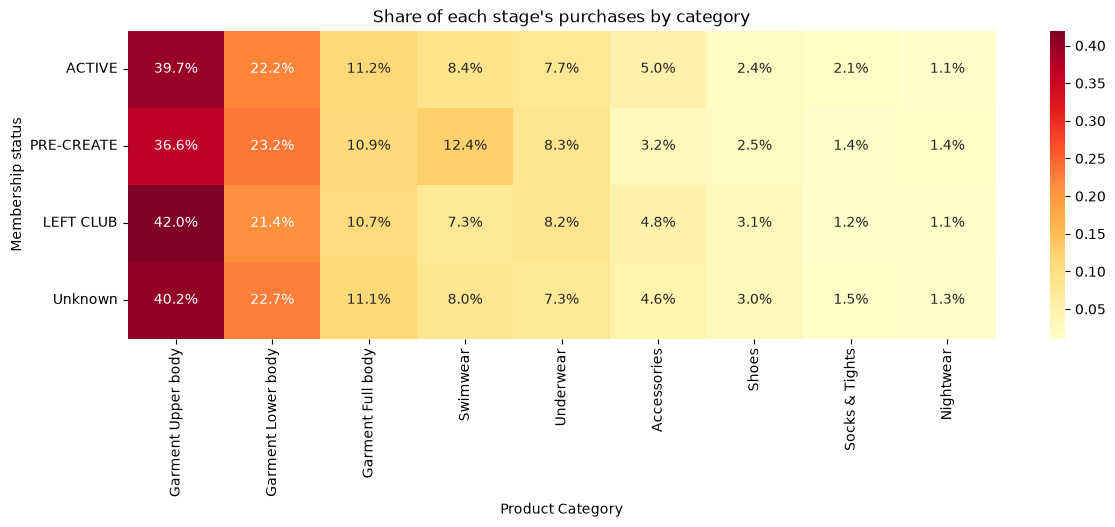

In [6]:
mix = pd.crosstab(df['club_member_status'], df['product_group_name']).reindex(order)

share = mix.div(mix.sum(axis=1), axis=0)          # share of each stage's purchases
overall = mix.sum() / mix.sum().sum()             # share of all purchases
main_cats = overall[overall >= 0.01].sort_values(ascending=False).index

plt.figure(figsize=(14, 4))
sns.heatmap(share[main_cats], cmap='YlOrRd', annot=True, fmt='.1%')
plt.title("Share of each stage's purchases by category")
plt.xlabel('Product Category')
plt.ylabel('Membership status')
plt.show()

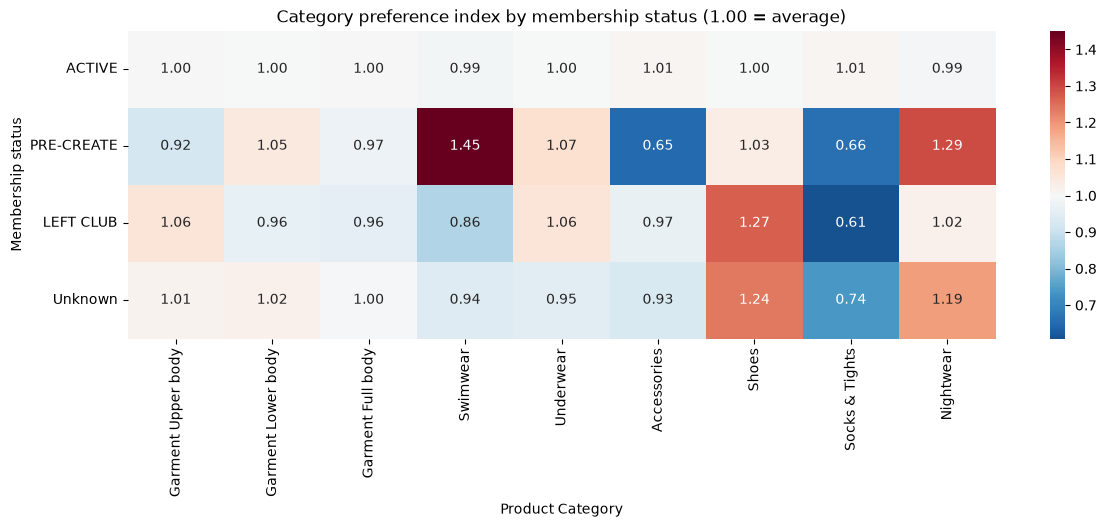

In [7]:
index = share.div(overall, axis=1)

plt.figure(figsize=(14, 4))
sns.heatmap(index[main_cats], cmap='RdBu_r', center=1, annot=True, fmt='.2f')
plt.title('Category preference index by membership status (1.00 = average)')
plt.xlabel('Product Category')
plt.ylabel('Membership status')
plt.show()

In [8]:
summary = pd.DataFrame({
    'purchases': mix.sum(axis=1),
    'most_over_indexed': index[main_cats].idxmax(axis=1),
    'index_high': index[main_cats].max(axis=1).round(2),
    'most_under_indexed': index[main_cats].idxmin(axis=1),
    'index_low': index[main_cats].min(axis=1).round(2),
})
summary

,purchases,most_over_indexed,index_high,most_under_indexed,index_low
club_member_status,,,,,
ACTIVE,15997833,Socks & Tights,1.01,Swimwear,0.99
PRE-CREATE,363620,Swimwear,1.45,Accessories,0.65
LEFT CLUB,5470,Shoes,1.27,Socks & Tights,0.61
Unknown,30007,Shoes,1.24,Socks & Tights,0.74


## 5. Findings

**Group sizes**
- ACTIVE accounts for about 98% of purchases. PRE-CREATE is about 2%, and LEFT CLUB and Unknown are each well under 1%. Raw totals only reflect group size, so I compared per-purchase measures.

**Price**
- The median price per purchase is identical across all four stages (0.025407), so the typical purchase costs the same whatever the status.
- Mean prices are slightly higher for PRE-CREATE, Unknown and LEFT CLUB than for ACTIVE (roughly 6-9%). The medians are equal, so this comes from a larger share of higher-priced purchases and not from a shift in the typical price.
- The effect is small. LEFT CLUB has only about 5,000 purchases, so its gap could partly be noise.

**Category mix**
- (From the index heatmap: which category does each non-active stage over-buy, and which does it under-buy? Name the largest index values from the summary table.)
- (Does the category mix explain the slightly higher means? If the non-active groups over-index on pricier categories, say so. If the mixes are nearly identical, say that the difference is not driven by category.)

**Business implication**
- (One or two sentences. For example, whether the data suggests membership status is a useful way to segment marketing, or whether behaviour is too similar to bother.)

**Limitations**
- The column has no true non-members: everyone has some relationship with the club, so "non-active" combines three different groups.
- ACTIVE is about 98% of the data, so comparisons use the small groups as the unusual side. Small groups give noisier results.
- Unknown is probably missing data, not a real stage, so treat its results with caution.
- Each row is one purchase and there is no customer id here, so this describes purchases, not individual customers.
- A single year of data, and prices are scaled, so differences are relative.